# Workshop 6: Scikit-learn

Completed implementations of all 11 tutorials listed in `DSWKSP6_sam.pdf`, including the optional SVM examples. Random seeds are fixed for reproducibility, and the two external datasets are stored locally.

## Original tutorial links

1. [K-Means](https://medium.com/@a4793706/機器學習-k-means-clustering-in-python-附程式碼介紹-55c19bcf2280)
2. [Naive Bayes Classification](https://www.datacamp.com/community/tutorials/naive-bayes-scikit-learn)
3. [Linear Regression](https://realpython.com/linear-regression-in-python/)
4. [Support Vector Machines (SVMs)](https://stackabuse.com/implementing-svm-and-kernel-svm-with-pythons-scikit-learn/)
5. [Decision Trees](https://www.datacamp.com/community/tutorials/decision-tree-classification-python)
6. [More on SVMs](https://scikit-learn.org/stable/modules/svm.html)
7. [SVM: Maximum margin separating hyperplane](https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane.html) (Optional)
8. [Non-linear SVM](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_nonlinear.html) (Optional)
9. [SVM-Anova](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_anova.html) (Optional)
10. [SVM: Separating hyperplane for unbalanced classes](https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane_unbalanced.html) (Optional)
11. [SVM: Weighted samples](https://scikit-learn.org/stable/auto_examples/svm/plot_weighted_samples.html) (Optional)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

DATA_DIR = Path("Lab6") if Path("Lab6").is_dir() else Path(".")
print(f"scikit-learn {sklearn.__version__}")
print(f"Data directory: {DATA_DIR.resolve()}")

scikit-learn 1.9.1
Data directory: /Users/shuokuro/Documents/Github/DIT5412-Data-Science/Lab6


## 1. K-Means

[Original tutorial](https://medium.com/@a4793706/機器學習-k-means-clustering-in-python-附程式碼介紹-55c19bcf2280). K-Means alternates between assigning each point to its nearest centroid and updating each centroid to the mean of its assigned points. The example below implements that loop directly, then compares it with scikit-learn's `k-means++` implementation.

In [2]:
from sklearn.datasets import make_blobs

X_kmeans, y_kmeans = make_blobs(
    n_samples=300, centers=3, cluster_std=0.8, random_state=42
)

def kmeans_from_scratch(X, n_clusters=3, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    centroids = X[rng.choice(len(X), n_clusters, replace=False)].copy()

    for iteration in range(1, max_iter + 1):
        distances = np.linalg.norm(
            X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2
        )
        labels = distances.argmin(axis=1)
        new_centroids = np.array([
            X[labels == cluster].mean(axis=0)
            if np.any(labels == cluster) else centroids[cluster]
            for cluster in range(n_clusters)
        ])
        if np.allclose(new_centroids, centroids):
            return labels, new_centroids, iteration
        centroids = new_centroids

    return labels, centroids, max_iter

manual_labels, manual_centroids, manual_iterations = kmeans_from_scratch(X_kmeans)
print(f"Converged in {manual_iterations} iterations")
print("Centroids:\n", manual_centroids)

Converged in 9 iterations
Centroids:
 [[ 1.0586164   5.5204112 ]
 [-7.26129873 -7.29673611]
 [-6.21053245 -6.37027257]]


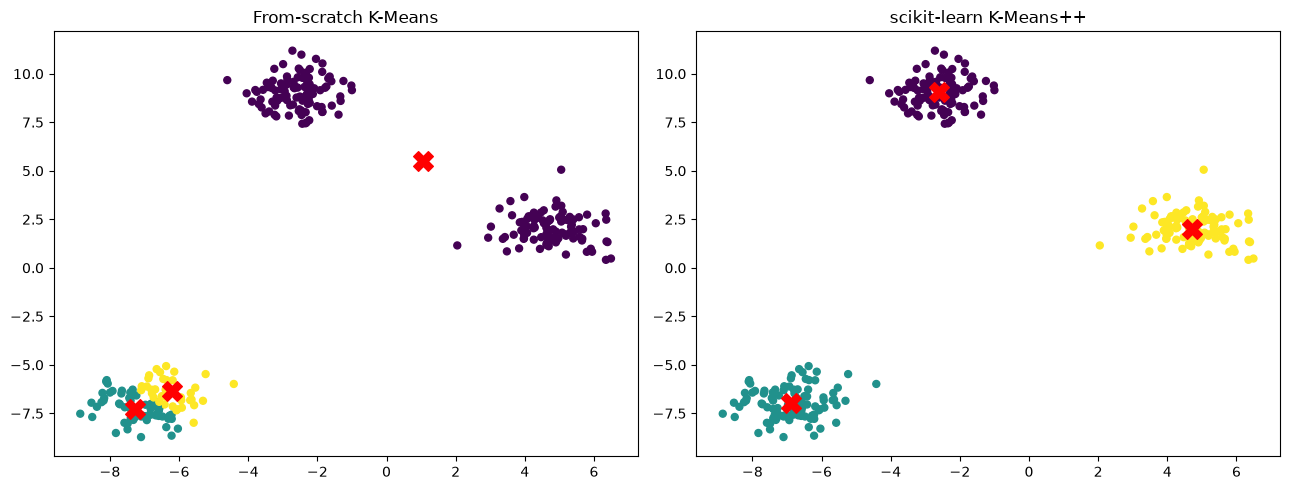

scikit-learn iterations: 2
Inertia: 362.790
Adjusted Rand index: 1.000


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

kmeans = KMeans(
    n_clusters=3, init="k-means++", n_init=10, random_state=42
).fit(X_kmeans)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, labels, centers, title in [
    (axes[0], manual_labels, manual_centroids, "From-scratch K-Means"),
    (axes[1], kmeans.labels_, kmeans.cluster_centers_, "scikit-learn K-Means++"),
]:
    ax.scatter(X_kmeans[:, 0], X_kmeans[:, 1], c=labels, s=25, cmap="viridis")
    ax.scatter(centers[:, 0], centers[:, 1], c="red", marker="X", s=200)
    ax.set_title(title)
plt.tight_layout()
plt.show()

print(f"scikit-learn iterations: {kmeans.n_iter_}")
print(f"Inertia: {kmeans.inertia_:.3f}")
print(f"Adjusted Rand index: {adjusted_rand_score(y_kmeans, kmeans.labels_):.3f}")

## 2. Naive Bayes Classification

[Original tutorial](https://www.datacamp.com/community/tutorials/naive-bayes-scikit-learn). Gaussian Naive Bayes models each feature as a Gaussian distribution within every class and assumes conditional independence between features. The tutorial's synthetic three-class workflow is reproduced below.

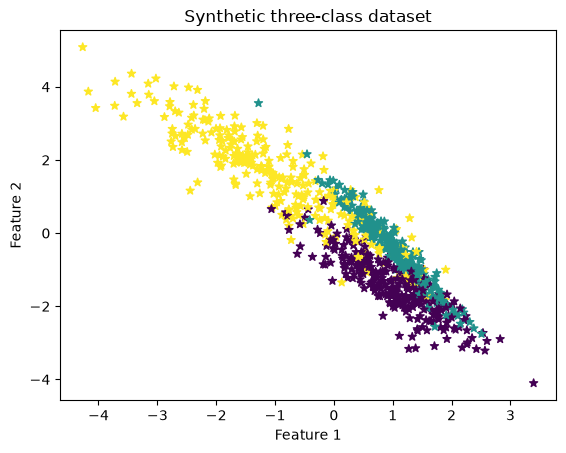

In [4]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X_nb, y_nb = make_classification(
    n_features=6,
    n_classes=3,
    n_samples=800,
    n_informative=2,
    n_clusters_per_class=1,
    random_state=1,
)
X_nb_train, X_nb_test, y_nb_train, y_nb_test = train_test_split(
    X_nb, y_nb, test_size=0.33, random_state=125
)

plt.scatter(X_nb[:, 0], X_nb[:, 1], c=y_nb, marker="*", cmap="viridis")
plt.title("Synthetic three-class dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Sample actual value: 0
Sample predicted value: 0
Accuracy: 0.8485
Weighted F1: 0.8479
              precision    recall  f1-score   support

           0       0.85      0.92      0.88        86
           1       0.79      0.87      0.83        95
           2       0.94      0.75      0.83        83

    accuracy                           0.85       264
   macro avg       0.86      0.85      0.85       264
weighted avg       0.86      0.85      0.85       264



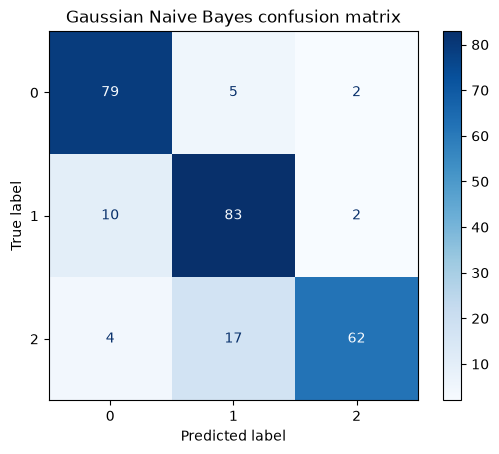

In [5]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB().fit(X_nb_train, y_nb_train)
sample_prediction = nb_model.predict(X_nb_test[[6]])
y_nb_pred = nb_model.predict(X_nb_test)

print(f"Sample actual value: {y_nb_test[6]}")
print(f"Sample predicted value: {sample_prediction[0]}")
print(f"Accuracy: {accuracy_score(y_nb_test, y_nb_pred):.4f}")
print(f"Weighted F1: {f1_score(y_nb_test, y_nb_pred, average='weighted'):.4f}")
print(classification_report(y_nb_test, y_nb_pred))

cm_nb = confusion_matrix(y_nb_test, y_nb_pred, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm_nb, display_labels=[0, 1, 2]).plot(cmap="Blues")
plt.title("Gaussian Naive Bayes confusion matrix")
plt.show()

In [6]:
p_yes = 9 / 14
p_no = 5 / 14
yes_score = (4 / 9) * (4 / 9) * p_yes
no_score = (0 / 5) * (2 / 5) * p_no
p_yes_normalized = yes_score / (yes_score + no_score)

print(f"Yes unnormalized score: {yes_score:.4f}")
print(f"No unnormalized score: {no_score:.4f}")
print(f"P(Yes | Overcast, Mild) = {p_yes_normalized:.2f}")
print("Prediction: play = Yes")

Yes unnormalized score: 0.1270
No unnormalized score: 0.0000
P(Yes | Overcast, Mild) = 1.00
Prediction: play = Yes


## 3. Linear Regression

[Original tutorial](https://realpython.com/linear-regression-in-python/). Each model follows the same five steps: import, provide/transform data, fit, evaluate with $R^2$, and predict. Simple, multiple, and polynomial regression are included.

R²: 0.7159
Intercept: 5.6333
Slope: 0.5400
Predictions for x = 0..4: [5.63333333 6.17333333 6.71333333 7.25333333 7.79333333]


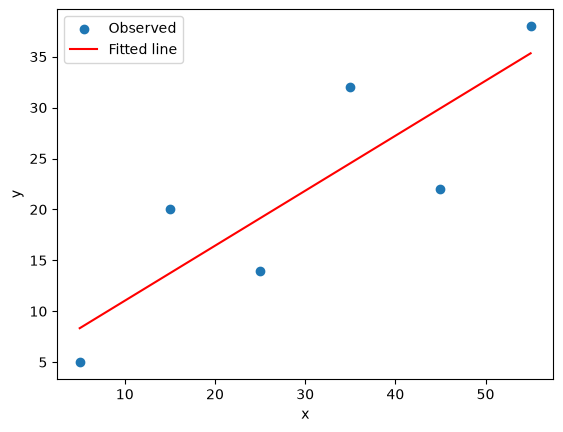

In [7]:
from sklearn.linear_model import LinearRegression

x_simple = np.array([5, 15, 25, 35, 45, 55]).reshape(-1, 1)
y_simple = np.array([5, 20, 14, 32, 22, 38])
simple_model = LinearRegression().fit(x_simple, y_simple)
x_simple_new = np.arange(5).reshape(-1, 1)

print(f"R²: {simple_model.score(x_simple, y_simple):.4f}")
print(f"Intercept: {simple_model.intercept_:.4f}")
print(f"Slope: {simple_model.coef_[0]:.4f}")
print(f"Predictions for x = 0..4: {simple_model.predict(x_simple_new)}")

plt.scatter(x_simple, y_simple, label="Observed")
plt.plot(x_simple, simple_model.predict(x_simple), color="red", label="Fitted line")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [8]:
x_multiple = np.array([
    [0, 1], [5, 1], [15, 2], [25, 5],
    [35, 11], [45, 15], [55, 34], [60, 35],
])
y_multiple = np.array([4, 5, 20, 14, 32, 22, 38, 43])
multiple_model = LinearRegression().fit(x_multiple, y_multiple)
x_multiple_new = np.arange(10).reshape(-1, 2)

print(f"R²: {multiple_model.score(x_multiple, y_multiple):.4f}")
print(f"Intercept: {multiple_model.intercept_:.4f}")
print(f"Coefficients: {multiple_model.coef_}")
print(f"New predictions: {multiple_model.predict(x_multiple_new)}")

R²: 0.8616
Intercept: 5.5226
Coefficients: [0.44706965 0.25502548]
New predictions: [ 5.77760476  7.18179502  8.58598528  9.99017554 11.3943658 ]


Simple polynomial R²: 0.9582
Intercept: 12.2080
Coefficients: [ 1.35928571 -0.00446429]


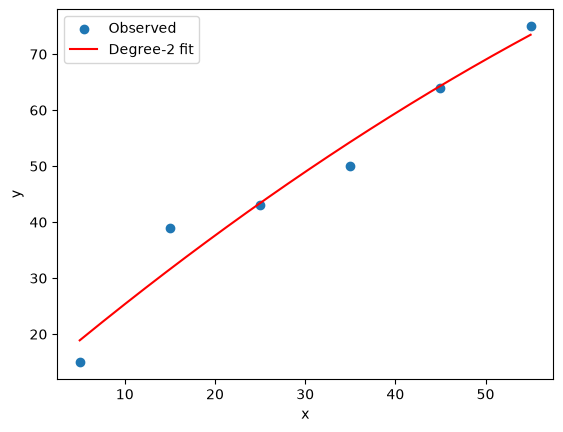

Multiple polynomial R²: 0.9454
Multiple polynomial coefficients: [ 2.44828275  0.16160353 -0.15259677  0.47928683 -0.4641851 ]


In [9]:
from sklearn.preprocessing import PolynomialFeatures

y_polynomial = np.array([15, 39, 43, 50, 64, 75])
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)
x_simple_poly = poly_transformer.fit_transform(x_simple)
poly_model = LinearRegression().fit(x_simple_poly, y_polynomial)
x_curve = np.linspace(5, 55, 200).reshape(-1, 1)

print(f"Simple polynomial R²: {poly_model.score(x_simple_poly, y_polynomial):.4f}")
print(f"Intercept: {poly_model.intercept_:.4f}")
print(f"Coefficients: {poly_model.coef_}")

plt.scatter(x_simple, y_polynomial, label="Observed")
plt.plot(
    x_curve,
    poly_model.predict(poly_transformer.transform(x_curve)),
    color="red",
    label="Degree-2 fit",
)
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

x_multiple_poly = poly_transformer.fit_transform(x_multiple)
multiple_poly_model = LinearRegression().fit(x_multiple_poly, y_multiple)
print(f"Multiple polynomial R²: {multiple_poly_model.score(x_multiple_poly, y_multiple):.4f}")
print(f"Multiple polynomial coefficients: {multiple_poly_model.coef_}")

## 4. Support Vector Machines (SVMs)

[Original tutorial](https://stackabuse.com/implementing-svm-and-kernel-svm-with-pythons-scikit-learn/). The banknote-authentication dataset contains four wavelet-derived measurements and a binary class. The data are explored, split into training/test sets, classified with a linear SVM, and then used to compare kernels.

,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


Shape: (1372, 5)
Class proportions:
class
0    0.555394
1    0.444606
Name: proportion, dtype: float64


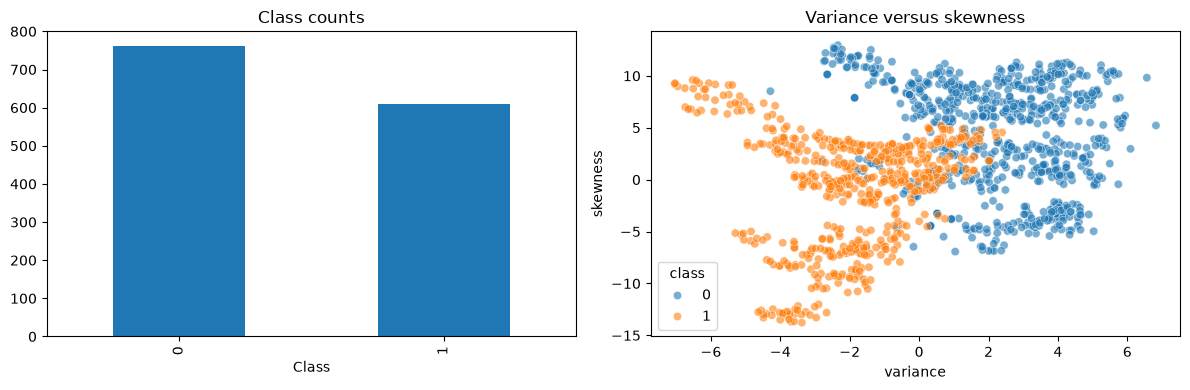

In [10]:
bank_columns = ["variance", "skewness", "curtosis", "entropy", "class"]
bankdata = pd.read_csv(
    DATA_DIR / "data_banknote_authentication.csv",
    names=bank_columns,
    header=None,
)
display(bankdata.head())
print(f"Shape: {bankdata.shape}")
print("Class proportions:")
print(bankdata["class"].value_counts(normalize=True).sort_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bankdata["class"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Class counts")
axes[0].set_xlabel("Class")
sns.scatterplot(
    data=bankdata, x="variance", y="skewness", hue="class", alpha=0.6, ax=axes[1]
)
axes[1].set_title("Variance versus skewness")
plt.tight_layout()
plt.show()

Training samples: 1097; test samples: 275
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       148
           1       0.98      0.98      0.98       127

    accuracy                           0.99       275
   macro avg       0.99      0.99      0.99       275
weighted avg       0.99      0.99      0.99       275



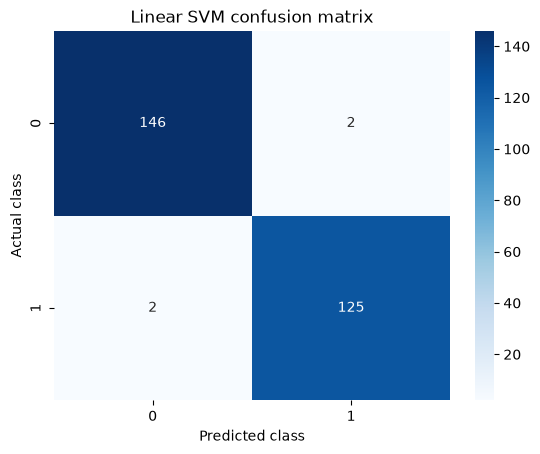

In [11]:
from sklearn.svm import SVC

X_bank = bankdata.drop("class", axis=1)
y_bank = bankdata["class"]
X_bank_train, X_bank_test, y_bank_train, y_bank_test = train_test_split(
    X_bank, y_bank, test_size=0.20, random_state=42
)
svc_linear = SVC(kernel="linear").fit(X_bank_train, y_bank_train)
y_bank_pred = svc_linear.predict(X_bank_test)

print(f"Training samples: {len(X_bank_train)}; test samples: {len(X_bank_test)}")
print(classification_report(y_bank_test, y_bank_pred))
cm_svm = confusion_matrix(y_bank_test, y_bank_pred)
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues")
plt.title("Linear SVM confusion matrix")
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.show()

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

kernel_scores = {}
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel, random_state=42))
    model.fit(X_bank_train, y_bank_train)
    kernel_scores[kernel] = model.score(X_bank_test, y_bank_test)

print("Test accuracy with standardized features:")
for kernel, score in kernel_scores.items():
    print(f"{kernel:>7}: {score:.4f}")

Test accuracy with standardized features:
 linear: 0.9855
   poly: 0.9891
    rbf: 1.0000
sigmoid: 0.7564


## 5. Decision Trees

[Original tutorial](https://www.datacamp.com/community/tutorials/decision-tree-classification-python). A decision tree recursively selects feature thresholds that separate the target classes. Both the tutorial's baseline tree and its entropy-based, depth-limited tree are fitted on the Pima diabetes dataset.

In [13]:
from sklearn.tree import DecisionTreeClassifier

pima_columns = [
    "pregnant", "glucose", "bp", "skin", "insulin",
    "bmi", "pedigree", "age", "label",
]
pima = pd.read_csv(DATA_DIR / "diabetes.csv", header=None, names=pima_columns)
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X_pima = pima[feature_cols]
y_pima = pima["label"]
X_pima_train, X_pima_test, y_pima_train, y_pima_test = train_test_split(
    X_pima, y_pima, test_size=0.3, random_state=1
)

tree_model = DecisionTreeClassifier(random_state=42).fit(X_pima_train, y_pima_train)
y_tree_pred = tree_model.predict(X_pima_test)
print(f"Baseline accuracy: {accuracy_score(y_pima_test, y_tree_pred):.4f}")
print(f"Tree depth: {tree_model.get_depth()}; leaves: {tree_model.get_n_leaves()}")
print(confusion_matrix(y_pima_test, y_tree_pred))

Baseline accuracy: 0.6883
Tree depth: 15; leaves: 104
[[117  29]
 [ 43  42]]


Entropy/max_depth=3 accuracy: 0.7706
              precision    recall  f1-score   support

           0       0.80      0.85      0.82       146
           1       0.71      0.64      0.67        85

    accuracy                           0.77       231
   macro avg       0.76      0.74      0.75       231
weighted avg       0.77      0.77      0.77       231



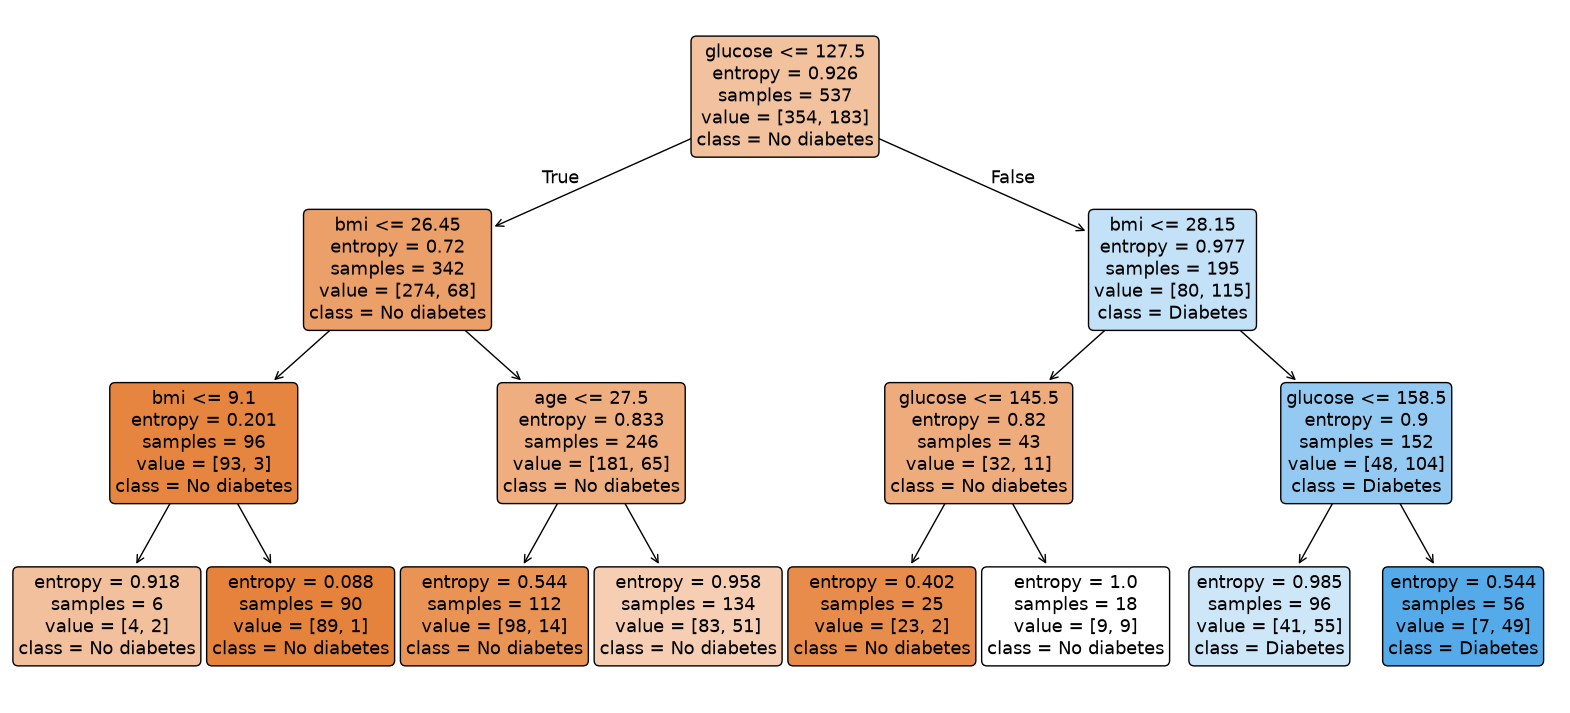

In [14]:
from sklearn.tree import plot_tree

tree_optimized = DecisionTreeClassifier(
    criterion="entropy", max_depth=3, random_state=42
).fit(X_pima_train, y_pima_train)
y_tree_optimized_pred = tree_optimized.predict(X_pima_test)
print(f"Entropy/max_depth=3 accuracy: {accuracy_score(y_pima_test, y_tree_optimized_pred):.4f}")
print(classification_report(y_pima_test, y_tree_optimized_pred))

plt.figure(figsize=(20, 9))
plot_tree(
    tree_optimized,
    feature_names=feature_cols,
    class_names=["No diabetes", "Diabetes"],
    filled=True,
    rounded=True,
)
plt.show()

## 6. More on SVMs

[Original guide](https://scikit-learn.org/stable/modules/svm.html). SVMs support classification, regression, and novelty detection. This section demonstrates the main estimators, support vectors, multiclass decision scores, feature scaling, and an RBF-kernel regressor.

In [15]:
from sklearn import svm
from sklearn.datasets import load_iris

X_tiny = np.array([[0, 0], [1, 1]])
y_tiny = np.array([0, 1])
tiny_svc = svm.SVC().fit(X_tiny, y_tiny)
print(f"Prediction for [2, 2]: {tiny_svc.predict([[2, 2]])[0]}")
print(f"Support vectors:\n{tiny_svc.support_vectors_}")
print(f"Support vectors per class: {tiny_svc.n_support_}")

X_iris, y_iris = load_iris(return_X_y=True)
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    X_iris, y_iris, test_size=0.25, stratify=y_iris, random_state=42
)
iris_svc = make_pipeline(StandardScaler(), svm.SVC()).fit(X_iris_train, y_iris_train)
iris_scores = iris_svc.decision_function(X_iris_test[:3])
print(f"Multiclass decision-score shape: {iris_scores.shape}")
print(f"Iris test accuracy: {iris_svc.score(X_iris_test, y_iris_test):.4f}")

Prediction for [2, 2]: 1
Support vectors:
[[0. 0.]
 [1. 1.]]
Support vectors per class: [1 1]
Multiclass decision-score shape: (3, 3)
Iris test accuracy: 0.9474


SVR R²: 0.9901
SVR prediction at x = 1: 0.7920


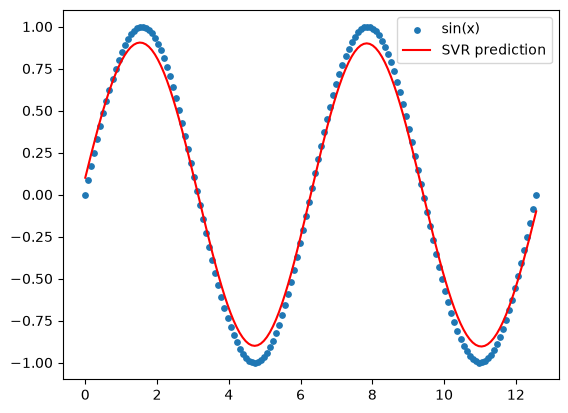

In [16]:
X_svr = np.linspace(0, 4 * np.pi, 150).reshape(-1, 1)
y_svr = np.sin(X_svr).ravel()
svr_model = make_pipeline(StandardScaler(), svm.SVR(C=10, epsilon=0.1)).fit(X_svr, y_svr)
y_svr_pred = svr_model.predict(X_svr)
print(f"SVR R²: {svr_model.score(X_svr, y_svr):.4f}")
print(f"SVR prediction at x = 1: {svr_model.predict([[1]])[0]:.4f}")

plt.scatter(X_svr, y_svr, s=15, label="sin(x)")
plt.plot(X_svr, y_svr_pred, color="red", label="SVR prediction")
plt.legend()
plt.show()

Points flagged as outliers: 10


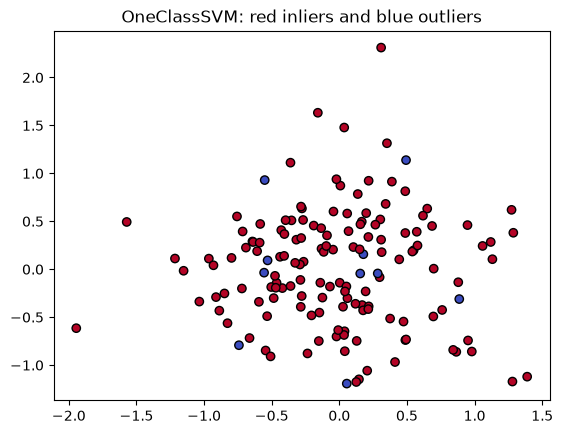

In [17]:
X_novelty, _ = make_blobs(n_samples=150, centers=[[0, 0]], cluster_std=0.6, random_state=42)
novelty_model = svm.OneClassSVM(kernel="rbf", gamma="scale", nu=0.05).fit(X_novelty)
novelty_labels = novelty_model.predict(X_novelty)
print(f"Points flagged as outliers: {np.sum(novelty_labels == -1)}")

plt.scatter(
    X_novelty[:, 0], X_novelty[:, 1],
    c=novelty_labels, cmap="coolwarm", edgecolors="k",
)
plt.title("OneClassSVM: red inliers and blue outliers")
plt.show()

## 7. SVM: Maximum Margin Separating Hyperplane (Optional)

[Official example](https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane.html). A high-`C` linear SVC separates two blobs. The solid line is the decision boundary, the dashed lines are the margins, and the circled points are support vectors.

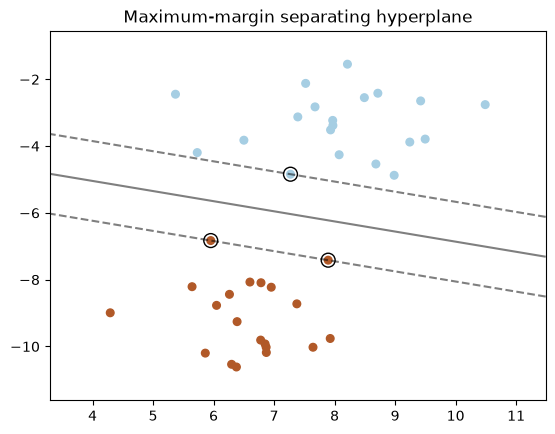

Number of support vectors: 3


In [18]:
from sklearn.inspection import DecisionBoundaryDisplay

X_margin, y_margin = make_blobs(n_samples=40, centers=2, random_state=6)
margin_svc = svm.SVC(kernel="linear", C=1000).fit(X_margin, y_margin)

plt.scatter(X_margin[:, 0], X_margin[:, 1], c=y_margin, s=30, cmap=plt.cm.Paired)
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    margin_svc,
    X_margin,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
    ax=ax,
)
ax.scatter(
    margin_svc.support_vectors_[:, 0],
    margin_svc.support_vectors_[:, 1],
    s=100,
    linewidth=1,
    facecolors="none",
    edgecolors="k",
)
ax.set_title("Maximum-margin separating hyperplane")
plt.show()
print(f"Number of support vectors: {len(margin_svc.support_vectors_)}")

## 8. Non-linear SVM (Optional)

[Official example](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_nonlinear.html). Linear, polynomial, RBF, and sigmoid kernels are compared first on a small non-linear dataset and then on the classic XOR pattern.

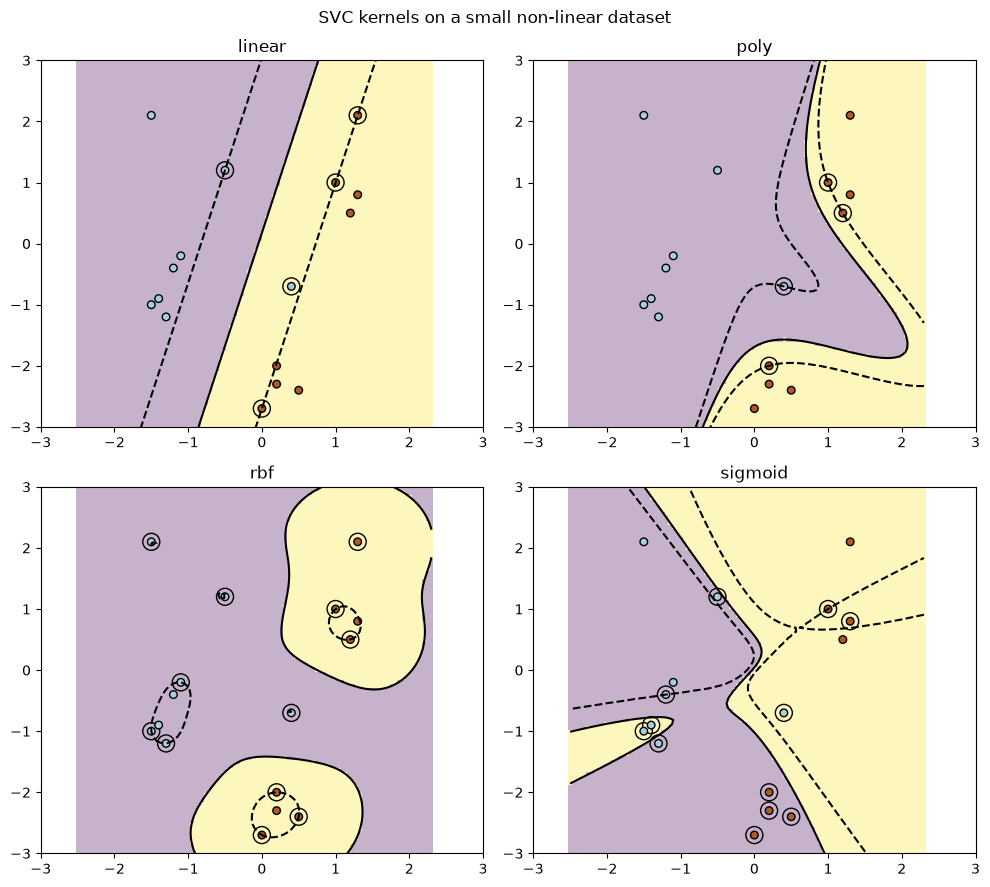

In [19]:
X_nonlinear = np.array([
    [0.4, -0.7], [-1.5, -1.0], [-1.4, -0.9], [-1.3, -1.2],
    [-1.1, -0.2], [-1.2, -0.4], [-0.5, 1.2], [-1.5, 2.1],
    [1.0, 1.0], [1.3, 0.8], [1.2, 0.5], [0.2, -2.0],
    [0.5, -2.4], [0.2, -2.3], [0.0, -2.7], [1.3, 2.1],
])
y_nonlinear = np.array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1])

def plot_svm_boundary(X, y, kernel, ax, support_vectors=True):
    classifier = svm.SVC(kernel=kernel, gamma=2).fit(X, y)
    DecisionBoundaryDisplay.from_estimator(
        classifier,
        X,
        response_method="predict",
        plot_method="pcolormesh",
        alpha=0.3,
        ax=ax,
    )
    DecisionBoundaryDisplay.from_estimator(
        classifier,
        X,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        colors="k",
        linestyles=["--", "-", "--"],
        ax=ax,
    )
    if support_vectors:
        ax.scatter(
            classifier.support_vectors_[:, 0],
            classifier.support_vectors_[:, 1],
            s=150,
            facecolors="none",
            edgecolors="k",
        )
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, edgecolors="k", cmap=plt.cm.Paired)
    ax.set(xlim=(-3, 3), ylim=(-3, 3))
    ax.set_title(kernel)
    return classifier

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for kernel, ax in zip(["linear", "poly", "rbf", "sigmoid"], axes.flat):
    plot_svm_boundary(X_nonlinear, y_nonlinear, kernel, ax)
fig.suptitle("SVC kernels on a small non-linear dataset")
plt.tight_layout()
plt.show()

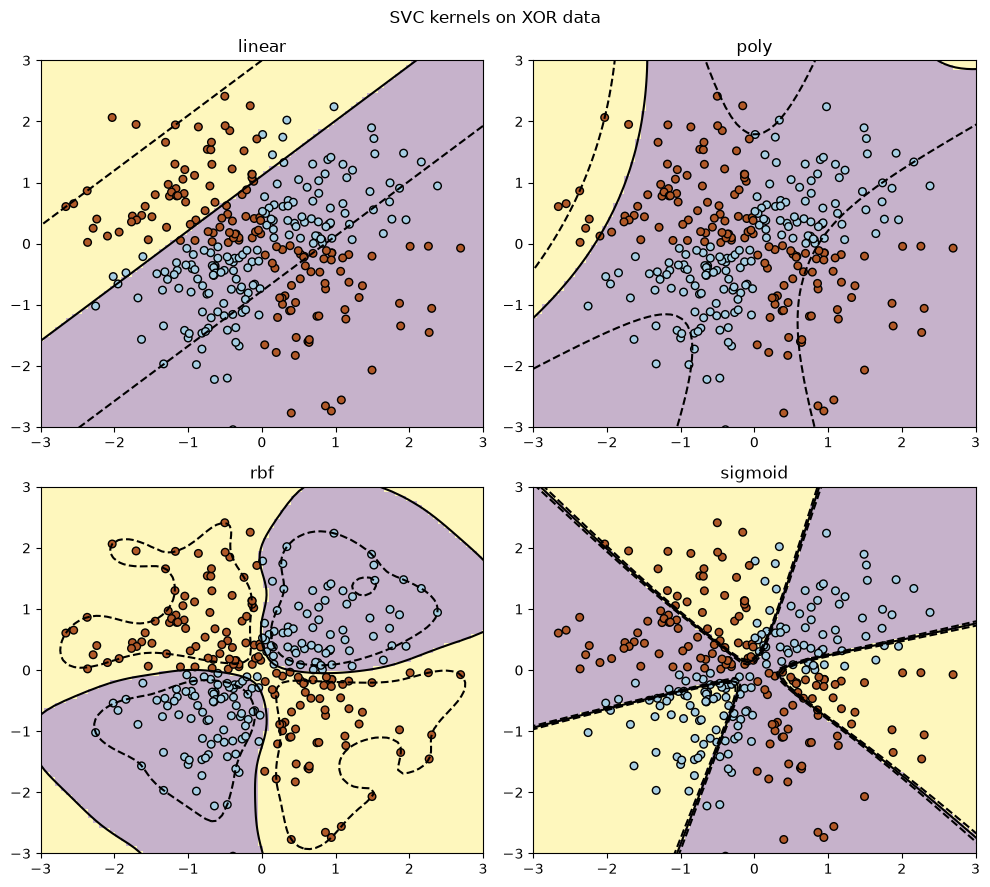

XOR training accuracy:
 linear: 0.6800
   poly: 0.5533
    rbf: 0.9867
sigmoid: 0.4933


In [20]:
rng_xor = np.random.RandomState(0)
X_xor = rng_xor.randn(300, 2)
y_xor = np.logical_xor(X_xor[:, 0] > 0, X_xor[:, 1] > 0)

fig, axes = plt.subplots(2, 2, figsize=(10, 9))
xor_models = {}
for kernel, ax in zip(["linear", "poly", "rbf", "sigmoid"], axes.flat):
    xor_models[kernel] = plot_svm_boundary(
        X_xor, y_xor, kernel, ax, support_vectors=False
    )
fig.suptitle("SVC kernels on XOR data")
plt.tight_layout()
plt.show()

print("XOR training accuracy:")
for kernel, model in xor_models.items():
    print(f"{kernel:>7}: {model.score(X_xor, y_xor):.4f}")

## 9. SVM-Anova: SVM with Univariate Feature Selection (Optional)

[Official example](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_anova.html). Thirty-six non-informative features are added to Iris. A pipeline selects a percentile of features with ANOVA F-values, scales them, and trains an SVC; cross-validation identifies a useful feature fraction.

,percentile,mean_accuracy,std
0,1,0.9533,0.0400
1,3,0.9600,0.0249
2,6,0.9533,0.0340
3,10,0.9667,0.0211
4,15,0.9467,0.0267
5,20,0.9000,0.0596
6,30,0.8733,0.0573
7,40,0.8533,0.0653
8,60,0.8533,0.0340
9,80,0.8000,0.0365


Best percentile: 10%; mean accuracy: 0.9667


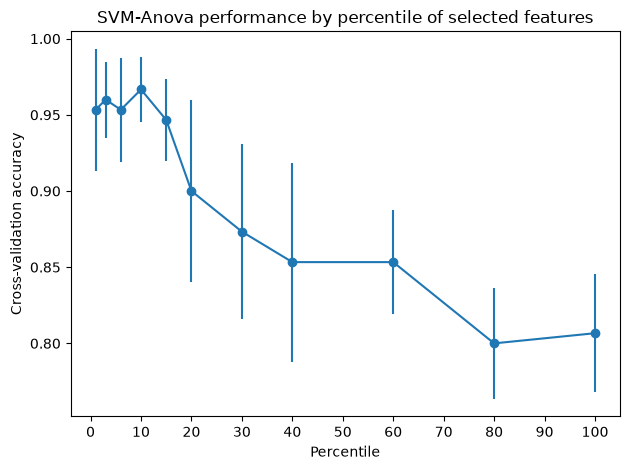

In [21]:
from sklearn.feature_selection import SelectPercentile, f_classif
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline

X_anova, y_anova = load_iris(return_X_y=True)
rng_anova = np.random.RandomState(0)
X_anova = np.hstack((X_anova, 2 * rng_anova.random((X_anova.shape[0], 36))))
anova_svc = Pipeline([
    ("anova", SelectPercentile(f_classif)),
    ("scaler", StandardScaler()),
    ("svc", SVC(gamma="auto")),
])

percentiles = (1, 3, 6, 10, 15, 20, 30, 40, 60, 80, 100)
score_means = []
score_stds = []
for percentile in percentiles:
    anova_svc.set_params(anova__percentile=percentile)
    scores = cross_val_score(anova_svc, X_anova, y_anova)
    score_means.append(scores.mean())
    score_stds.append(scores.std())

anova_results = pd.DataFrame({
    "percentile": percentiles,
    "mean_accuracy": score_means,
    "std": score_stds,
})
display(anova_results.round(4))
best = anova_results.loc[anova_results["mean_accuracy"].idxmax()]
print(f"Best percentile: {best['percentile']:.0f}%; mean accuracy: {best['mean_accuracy']:.4f}")

plt.errorbar(percentiles, score_means, yerr=np.array(score_stds), marker="o")
plt.title("SVM-Anova performance by percentile of selected features")
plt.xticks(np.linspace(0, 100, 11, endpoint=True))
plt.xlabel("Percentile")
plt.ylabel("Cross-validation accuracy")
plt.tight_layout()
plt.show()

## 10. SVM: Separating Hyperplane for Unbalanced Classes (Optional)

[Official example](https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane_unbalanced.html). The minority class contains 100 points and the majority class 1,000. Giving class 1 ten times the weight shifts the boundary to improve minority-class recognition.

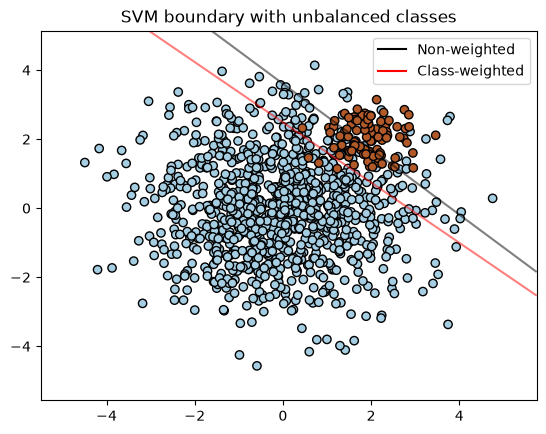

Non-weighted: class 0 recall=0.9760, class 1 recall=0.5900


Class-weighted: class 0 recall=0.9040, class 1 recall=0.9700


In [22]:
import matplotlib.lines as mlines
from sklearn.metrics import recall_score

X_unbalanced, y_unbalanced = make_blobs(
    n_samples=[1000, 100],
    centers=[[0.0, 0.0], [2.0, 2.0]],
    cluster_std=[1.5, 0.5],
    random_state=0,
    shuffle=False,
)
unweighted_svc = svm.SVC(kernel="linear", C=1.0).fit(X_unbalanced, y_unbalanced)
class_weighted_svc = svm.SVC(
    kernel="linear", class_weight={1: 10}
).fit(X_unbalanced, y_unbalanced)

plt.scatter(
    X_unbalanced[:, 0], X_unbalanced[:, 1],
    c=y_unbalanced, cmap=plt.cm.Paired, edgecolors="k",
)
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    unweighted_svc, X_unbalanced, plot_method="contour", colors="k",
    levels=[0], alpha=0.5, linestyles=["-"], ax=ax,
)
DecisionBoundaryDisplay.from_estimator(
    class_weighted_svc, X_unbalanced, plot_method="contour", colors="r",
    levels=[0], alpha=0.5, linestyles=["-"], ax=ax,
)
ax.legend(
    [
        mlines.Line2D([], [], color="k", label="Non-weighted"),
        mlines.Line2D([], [], color="r", label="Class-weighted"),
    ],
    ["Non-weighted", "Class-weighted"],
    loc="upper right",
)
ax.set_title("SVM boundary with unbalanced classes")
plt.show()

for name, model in [
    ("Non-weighted", unweighted_svc),
    ("Class-weighted", class_weighted_svc),
]:
    predictions = model.predict(X_unbalanced)
    recalls = recall_score(y_unbalanced, predictions, average=None)
    print(f"{name}: class 0 recall={recalls[0]:.4f}, class 1 recall={recalls[1]:.4f}")

## 11. SVM: Weighted Samples (Optional)

[Official example](https://scikit-learn.org/stable/auto_examples/svm/plot_weighted_samples.html). Individual `sample_weight` values rescale each point's regularization penalty. Larger markers represent larger weights; positive-class points receive extra weight in the second model.

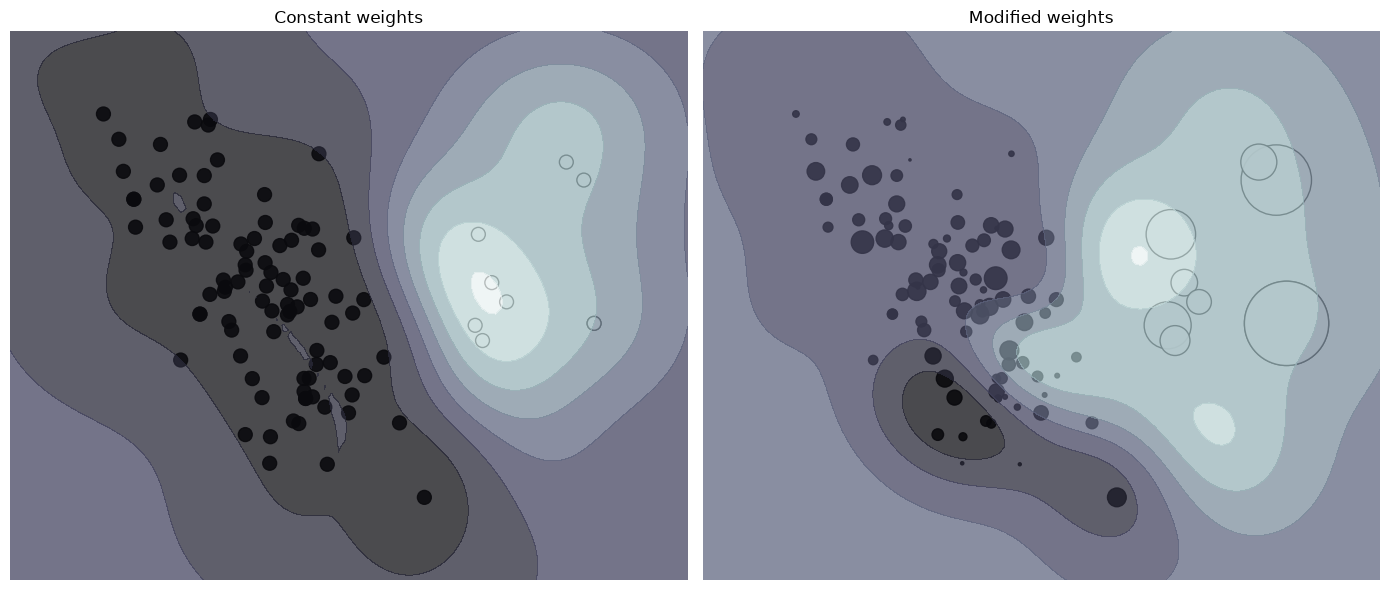

No weights: class 0 recall=0.9978, class 1 recall=0.7547
Sample weights: class 0 recall=0.8591, class 1 recall=0.9434


In [23]:
X_weighted, y_weighted = make_classification(
    n_samples=1_000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    class_sep=1.1,
    weights=[0.9, 0.1],
    random_state=0,
)
rng_weighted = np.random.RandomState(0)
plot_indices = rng_weighted.choice(np.arange(X_weighted.shape[0]), size=100, replace=True)
X_weighted_plot = X_weighted[plot_indices]
y_weighted_plot = y_weighted[plot_indices]

def plot_weighted_decision_function(classifier, sample_weight, axis, title):
    axis.scatter(
        X_weighted_plot[:, 0],
        X_weighted_plot[:, 1],
        c=y_weighted_plot,
        s=100 * sample_weight[plot_indices],
        alpha=0.9,
        cmap=plt.cm.bone,
        edgecolors="black",
    )
    DecisionBoundaryDisplay.from_estimator(
        classifier,
        X_weighted_plot,
        response_method="decision_function",
        alpha=0.75,
        ax=axis,
        cmap=plt.cm.bone,
    )
    axis.axis("off")
    axis.set_title(title)

sample_weight_constant = np.ones(len(X_weighted))
sample_weight_modified = abs(rng_weighted.randn(len(X_weighted)))
positive_class_indices = np.asarray(y_weighted == 1).nonzero()[0]
sample_weight_modified[positive_class_indices] *= 15

svc_no_weights = SVC(gamma=1).fit(X_weighted, y_weighted)
svc_sample_weights = SVC(gamma=1).fit(
    X_weighted, y_weighted, sample_weight=sample_weight_modified
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_weighted_decision_function(
    svc_no_weights, sample_weight_constant, axes[0], "Constant weights"
)
plot_weighted_decision_function(
    svc_sample_weights, sample_weight_modified, axes[1], "Modified weights"
)
plt.tight_layout()
plt.show()

for name, model in [("No weights", svc_no_weights), ("Sample weights", svc_sample_weights)]:
    predictions = model.predict(X_weighted)
    recalls = recall_score(y_weighted, predictions, average=None)
    print(f"{name}: class 0 recall={recalls[0]:.4f}, class 1 recall={recalls[1]:.4f}")